In [1]:
# analyze all the pythia experiments
import torch
import matplotlib.pyplot as plt

In [2]:
# models = ['410m', '12b', '2.8b', '70m']
models = ['70M', '160M', '410M', '1B' ,'1.4B', '2.8B', '6.9B', '12B']
file_postfix = ['3', '4', '0-1', '7','5', '2', '6', '1']
fit_range = [slice(1,-2), slice(2,-2), slice(2,None), slice(2,None), slice(2,None), slice(2,None), slice(2,None), slice(2,None)]

In [3]:
data = [torch.load(f'../outputs/pythia-logit-{postfix}.pt',weights_only=False) for postfix in file_postfix]
loss = [d['loss'] for d in data]
logit_std = [d['logit_std'] for d in data]

loss[2] = loss[2][7:]
logit_std[2] = logit_std[2][7:]

In [4]:
from scipy import optimize
import numpy as np

def residuals(x, c_l, alpha_l, L0):
    return np.log((c_l / (x ** alpha_l) + L0))

In [5]:
steps = [128, 256, 512, 1000, 2000, 3000, 6000, 12000, 16000, 32000, 48000, 79000, 143000]
def lr_scheduler(step, total_steps = 143000):
    # linear warmup 0.01 + cosine decay to 0.1 max lr
    step = torch.tensor(step)
    if step < total_steps * 0.01:
        return step / (total_steps * 0.01)
    else:
        progress = (step - total_steps * 0.01) / (total_steps * 0.99)
        return 0.5 * (1.0 + torch.cos(torch.pi * progress)) * 0.9 + 0.1

lrs = torch.tensor([lr_scheduler(step) for step in range(1,143001)])
tau = torch.tensor([lrs[:step].sum() for step in steps])
del lrs

steps = torch.tensor(steps)

In [6]:
max_lrs = [1e-3, 6e-4, 3e-4, 3e-4, 2e-4, 1.6e-4, 1.2e-4, 1.2e-4]

In [7]:
c_taus = []
alpha_taus = []
alpha_std_taus = []
L0_taus = []

for i in range(8):
        fitout = optimize.curve_fit(residuals, tau[fit_range[i]].numpy(), 
                                    loss[i].log()[fit_range[i]].numpy(), 
                                    p0=[1,0.33,loss[i][-1].item()],
                                            bounds = ([0,0,0], [np.inf,np.inf,loss[i][-1].item()]))
    
        c_taus.append(fitout[0][0])
        alpha_taus.append(fitout[0][1])
        alpha_std_taus.append(np.sqrt(np.diag(fitout[1]))[1])
        L0_taus.append(fitout[0][2])

In [8]:
for i in range(8):
    print(fr'{alpha_taus[i]}$\pm${alpha_std_taus[i]}')
#alpha_taus, alpha_std_taus

0.34071961515447385$\pm$0.02781450415735331
0.38327987572671096$\pm$0.014948134595400118
0.3670317571265018$\pm$0.01289855974771548
0.339976068406051$\pm$0.014652152552205868
0.3351111783496842$\pm$0.010117513143638275
0.33744748310751993$\pm$0.012964239150829605
0.314730858894706$\pm$0.019420434004427764
0.3073649904236741$\pm$0.016449714708779192


Text(0, 0.5, 'Test loss')

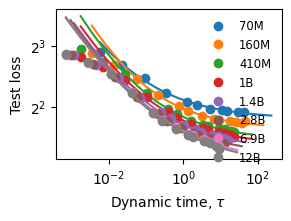

In [9]:
plt.figure(figsize=(2.8,2.1), constrained_layout=True)
plot_x = torch.logspace(torch.log10(tau[0]), torch.log10(tau[-1]*3), steps=100)
plt.plot(tau[:-2].numpy() * max_lrs[0], loss[0][:-2].numpy(), 'o', label=models[0], color = 'C0')
plt.plot(plot_x.numpy() * max_lrs[0], 
         (c_taus[0] / (plot_x.numpy() ** (alpha_taus[0])) + L0_taus[0]), 
         '-', color = 'C0')
for i in range(1,8):
    plt.plot(tau.numpy() * max_lrs[i], loss[i].numpy(), 'o', label=models[i], color = f'C{i}')
    plt.plot(plot_x.numpy() * max_lrs[i], 
             (c_taus[i] / (plot_x.numpy() ** (alpha_taus[i])) + L0_taus[i]), 
             '-', color = f'C{i}')

plt.xscale('log')
plt.yscale('log',base = 2)
plt.legend(frameon=False,fontsize = 'small')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Test loss')

Text(0, 0.5, 'Test loss (training part)')

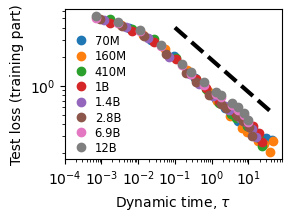

In [10]:
plt.figure(figsize=(2.8,2.1), constrained_layout=True)
plt.plot(tau[:-2].numpy() * max_lrs[0], loss[0][:-2].numpy() - L0_taus[0], 'o', label=models[0])
for i in range(1,8):
    plt.plot(tau.numpy() * max_lrs[i], loss[i].numpy() - L0_taus[i], 'o', label=models[i])
plt.plot([1e-1,5e+1], [4, 4 / (5e+2)**(1/3)], 'k--', linewidth=3)
plt.legend(frameon=False, fontsize = 'small', labelspacing=0.2, handletextpad=0.2, borderaxespad=0)
plt.xlim(1e-4, 8e+1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Test loss (training part)')

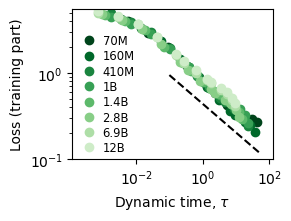

In [11]:
cmap=plt.get_cmap('Greens')
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
plt.plot(tau[:-2].numpy() * max_lrs[0], loss[0][:-2].numpy() - L0_taus[0], 'o', color = cmap(1.0), label=models[0])
plt.plot(tau[:-1].numpy() * max_lrs[1], loss[1][:-1].numpy() - L0_taus[1], 'o', color = cmap((9-1)/9), label=models[1])
for i in range(2,8):
    plt.plot(tau.numpy() * max_lrs[i], loss[i].numpy() - L0_taus[i], 'o', color = cmap((9-i)/9), label=models[i])
plot_x = torch.logspace(np.log10(1e-1), np.log10(5e+1), steps=100)
plt.plot(plot_x.numpy(), 0.5 * c_taus[0] / (plot_x.numpy() ** (1/3)) / 10, 'k--', linewidth=1.5)
plt.legend(frameon=False, fontsize = 'small', labelspacing=0.2, handletextpad=0.2, borderaxespad=0)
plt.xlim(2**-13, 2**7)
plt.ylim(1e-1, None)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Loss (training part)')
#plt.savefig('../../FitScaling/figures/pythia-tau.pdf')
plt.savefig('../../DistillScaling/figures/pythia-tau.pdf')

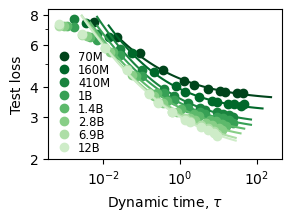

In [37]:
plt.figure(figsize=(2.8,2.1), constrained_layout=True)
plot_x = torch.logspace(torch.log10(tau[1]), torch.log10(tau[-1]*3), steps=100)
i = 0
plt.plot(tau[:-2].numpy() * max_lrs[0], loss[0][:-2].numpy(), 'o', label=models[0], color = cmap((9-i)/9))
plt.plot(plot_x.numpy() * max_lrs[0], 
         (c_taus[0] / (plot_x.numpy() ** (alpha_taus[0])) + L0_taus[0]), 
         '-', color = cmap((9-0)/9))
for i in range(1,8):
    plt.plot(tau.numpy() * max_lrs[i], loss[i].numpy(), 'o', label=models[i], color = cmap((9-i)/9))
    plt.plot(plot_x.numpy() * max_lrs[i], 
             (c_taus[i] / (plot_x.numpy() ** (alpha_taus[i])) + L0_taus[i]), 
             '-', color = cmap((9-i)/9))

#plt.ylim(2,None)
plt.xscale('log')
plt.yscale('log')
plt.yticks([2, 3, 4, 6, 8], ['2', '3', '4', '6', '8'])
plt.legend(frameon=False, fontsize = 'small', labelspacing=0.0, handletextpad=0.2, borderaxespad=0, loc='lower left')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Test loss')
plt.savefig('../../DistillScaling/figures/raw_loss.pdf')

In [11]:
L0_taus

[3.47963847710932,
 3.0218364761704346,
 2.667308782478832,
 2.563794109782662,
 2.451017946447755,
 2.316523985026373,
 2.203194743235363,
 2.145449446809168]

Text(0, 0.5, 'Logit std')

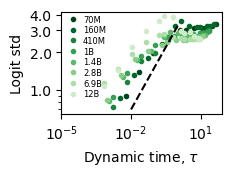

In [ ]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
plt.plot(tau[:-2].numpy() * max_lrs[0], logit_std[0][:-2].numpy(), 'o', color = cmap(1.0), label=models[0],markersize=3)
plt.plot(tau[:-1].numpy() * max_lrs[1], logit_std[1][:-1].numpy(), 'o', color = cmap((9-1)/9), label=models[1], markersize=3)
for i in range(2,8):
    plt.plot(tau.numpy() * max_lrs[i], logit_std[i].numpy(), 'o', color = cmap((9-i)/9), label=models[i], markersize=3)
plot_x = torch.logspace(np.log10(1e-2), np.log10(5e+1), steps=100)
#plt.plot(plot_x.numpy(), 0.5 * c_taus[0] / (plot_x.numpy() ** (1/3)) / 10, 'k--', linewidth=1.5)
plt.plot([1e-2,1], [7e-1, 7e-1 * (1e+2)**(1/3)], 'k--', linewidth=1.5)
plt.legend(frameon=False, fontsize = '6', labelspacing=0.2, handletextpad=0.2, borderaxespad=0)
plt.xlim(1e-5, 8e+1)
plt.xscale('log')
plt.yscale('log')
plt.yticks([1.0, 2.0, 3.0, 4.0], labels=['1.0', '2.0', '3.0', '4.0'])
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Logit std')
#plt.savefig('../../DistillScaling/figures/pythia-logits.pdf')

In [ ]:
logit_std[-1], tau.numpy() * max_lrs[-1]

(tensor([1.0735, 1.4403, 2.1971, 2.9891, 3.5922, 3.8930, 3.8321, 2.9502, 2.8603,
         2.9121, 2.6925, 2.6302, 2.5793]),
 array([6.9281115e-04, 2.7605034e-03, 1.1020531e-02, 4.1999996e-02,
        1.5425918e-01, 2.7424282e-01, 6.3383704e-01, 1.3490397e+00,
        1.8206218e+00, 3.6305203e+00, 5.2499218e+00, 7.6113267e+00,
        9.4294252e+00], dtype=float32))

Given the loss form
$$
L = \frac{c_m}{m} + \frac{c_\ell}{\ell} + \frac{c_\tau}{\tau^{1/3}} + L_0,
$$
where $m$ is width, $\ell$ is depth, and $\tau$ is the dynamic time, we can fit the constants $c_m$, $c_\ell$, $c_\tau$.
The relationship between dynamic time $\tau$ and the number of tokens $D$ is roughly
$$
\tau = \frac{1}{2}\frac{D}{B}\eta,
$$
where $B = 2\times 10^6$ is the batch size and $\eta$ is the peak learning rate in max_lrs.
We then have
$$
\frac{c_\tau}{\tau^{1/3}} = \frac{c_D}{D^{1/3}},
$$
with
$$
c_D = \frac{c_\tau}{(\frac{\eta}{2B})^{1/3}}.
$$

Since the number of parameters $N$ is roughly $12m^2\ell$, the optimal loss for a given $N$ is
$$
L = \frac{c_N}{N^{1/3}} + \frac{c_D}{D^{1/3}} + L_0,
$$
where
$$
c_N = 3^{4/3} c_m^{2/3} c_\ell^{1/3}.
$$
And the optimal width depth ratio is
$$
\frac{m}{\ell} = \frac{c_m}{2 c_\ell}.
$$
Since compute $C$ is roughly $6ND$, the optimal loss for a given $C$ is
$$
L = \frac{c_C}{C^{1/6}} + L_0,
$$
where
$$
c_C = 2 \cdot 6^{1/6} c_N^{1/2} c_D^{1/2}.
$$
And the optimal token to parameter ratio is
$$
\frac{D}{N} = \left(\frac{c_D}{c_N}\right)^3.
$$

## Uncertainty Estimation

We quantify uncertainties on all fitted and derived constants via two complementary sources.

**Fitting $c_\tau$.** For each of the $K = 8$ model sizes, we independently fit $c_{\tau,k}$ by nonlinear least squares to the temporal loss curve. Under the assumption that $c_\tau$ is a universal constant shared across model sizes, the $K$ estimates $\{c_{\tau,k}\}$ constitute $K$ independent measurements of the same quantity. Their sample standard deviation,
$$
\sigma_{c_\tau} = \sqrt{\frac{1}{K-1}\sum_{k=1}^{K}(c_{\tau,k} - \bar{c}_\tau)^2},
$$
is then the empirical standard error of a single per-model estimate, and we report $\bar{c}_\tau \pm \sigma_{c_\tau}$.

**Converting to $c_D$.** The dynamic time and token count are related by $\tau = \frac{\eta}{2B} D$, where $\eta$ is the peak learning rate and $B = 2\times10^6$ is the batch size. Substituting gives $c_D = c_\tau / (\eta/2B)^{1/3}$. We apply this transformation to each $c_{\tau,k}$ to obtain $\{c_{D,k}\}$, and report $\bar{c}_D \pm \sigma_{c_D}$ analogously.

**Fitting $c_m$ and $c_\ell$.** The representation loss $L_0$ fitted for each model is jointly regressed on width $m$ and depth $\ell$ via
$$
L_0 = \frac{c_m}{m} + \frac{c_\ell}{\ell} + L_\infty.
$$
The standard errors $\sigma_{c_m}$ and $\sigma_{c_\ell}$ are taken from the square root of the diagonal of the covariance matrix returned by the nonlinear least-squares solver, i.e., $\sigma_{c_m} = \sqrt{\Sigma_{11}}$ and $\sigma_{c_\ell} = \sqrt{\Sigma_{22}}$.

**Error propagation.** The derived constants $c_N$, $c_C$, the optimal width-to-depth ratio $m/\ell$, and the optimal token-to-parameter ratio $D/N$ are all monomials in the primary constants $c_m$, $c_\ell$, $c_D$. For a quantity of the form $f = A \prod_i x_i^{\alpha_i}$, standard first-order error propagation gives
$$
\frac{\sigma_f}{f} = \sqrt{\sum_i \alpha_i^2 \left(\frac{\sigma_{x_i}}{x_i}\right)^2},
$$
assuming the primary uncertainties are uncorrelated. Applying this to each derived quantity:

$$
\frac{\sigma_{c_N}}{c_N} = \sqrt{\left(\frac{2}{3}\frac{\sigma_{c_m}}{c_m}\right)^2 + \left(\frac{1}{3}\frac{\sigma_{c_\ell}}{c_\ell}\right)^2}, \qquad
\frac{\sigma_{m/\ell}}{m/\ell} = \sqrt{\left(\frac{\sigma_{c_m}}{c_m}\right)^2 + \left(\frac{\sigma_{c_\ell}}{c_\ell}\right)^2},
$$

$$
\frac{\sigma_{c_C}}{c_C} = \frac{1}{2}\sqrt{\left(\frac{\sigma_{c_N}}{c_N}\right)^2 + \left(\frac{\sigma_{c_D}}{c_D}\right)^2}, \qquad
\frac{\sigma_{D/N}}{D/N} = 3\sqrt{\left(\frac{\sigma_{c_D}}{c_D}\right)^2 + \left(\frac{\sigma_{c_N}}{c_N}\right)^2}.
$$


## Parametric Bootstrap for Uncertainty Quantification

To obtain confidence intervals on the derived scaling constants, we employ a parametric bootstrap procedure. Because the Pythia suite contains only $K = 8$ model sizes, non-parametric bootstrap (resampling with replacement) would yield poor coverage; parametric bootstrap instead draws synthetic parameter sets from the fitted distributions, propagating uncertainty through the nonlinear expressions for $c_N$, $c_C$, $m/\ell$, and $D/N$.

We draw $M = 10^5$ independent parameter sets as follows. The architectural constants $(c_m, c_\ell)$ are drawn jointly from the bivariate normal distribution implied by the nonlinear least-squares fit,
$$
(c_m, c_\ell) \sim \mathcal{N}\!\left(\hat{\boldsymbol{\theta}},\, \boldsymbol{\Sigma}\right),
$$
where $\hat{\boldsymbol{\theta}} = (\hat{c}_m, \hat{c}_\ell)$ and $\boldsymbol{\Sigma}$ is the $2\times 2$ leading submatrix of the covariance matrix returned by the solver. Drawing jointly preserves the correlation between $c_m$ and $c_\ell$ induced by fitting them to the same data. The data constant $c_D$ is drawn independently,
$$
c_D \sim \mathcal{N}(\bar{c}_D,\, \sigma_{c_D}),
$$
where $\bar{c}_D$ and $\sigma_{c_D}$ are the mean and standard deviation of the $K$ per-model estimates.

For each draw we evaluate $c_N = 3^{4/3} c_m^{2/3} c_\ell^{1/3}$, $m/\ell = c_m / 2c_\ell$, $c_C = 2\cdot 6^{1/6} c_N^{1/2} c_D^{1/2}$, and $D/N = (c_D/c_N)^3$, yielding an empirical distribution for each quantity. The 95\% confidence interval is reported as the 2.5th and 97.5th percentiles of this distribution, making no assumption about the shape of the propagated uncertainty.
